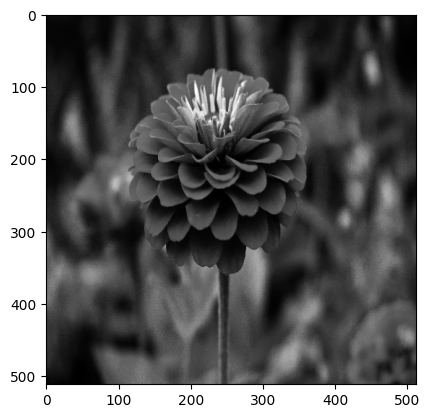

In [14]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('img.jpg', cv2.IMREAD_GRAYSCALE)
image = cv2.resize(image, (512, 512))
plt.imshow(image, cmap='gray')


In [15]:
def haar(image, levels):
    coeffs = image.astype(np.float32).copy()
    for level in range(levels):
        size = coeffs.shape[0] >> level
        block = coeffs[:size, :size]

        averages = (block[:, 0::2] + block[:, 1::2]) / 2
        details = (block[:, 0::2] - block[:, 1::2]) / 2
        block = np.concatenate((averages, details), axis=1)

        averages = (block[0::2, :] + block[1::2, :]) / 2
        details = (block[0::2, :] - block[1::2, :]) / 2
        block = np.concatenate((averages, details), axis=0)

        coeffs[:size, :size] = block
    return coeffs


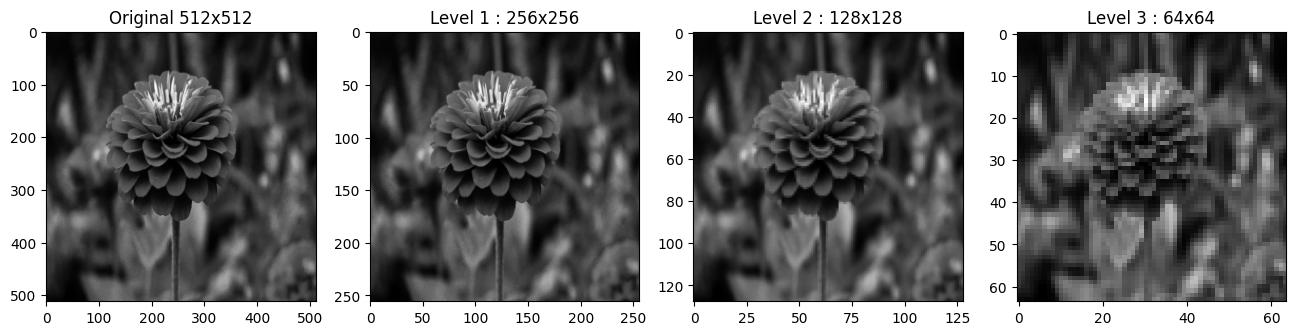

In [16]:
plt.figure(figsize=(16, 4))
plt.subplot(141)
plt.imshow(image, cmap='gray')
plt.title('Original 512x512')

for level in range(1, 4):
    coeffs = haar(image, level)
    size = image.shape[0] >> level
    plt.subplot(1, 4, level + 1)
    plt.imshow(coeffs[:size, :size], cmap='gray')
    plt.title(f'Level {level} : {size}x{size}')
plt.show()
